In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

!rm -rf codsoft-projects
!git clone https://github.com/Priyadh1/codsoft-projects.git

df = pd.read_csv("codsoft-projects/Task2_Movie_Rating/IMDb Movies India.csv", encoding="latin-1")

print("Shape:", df.shape)
print("Movies with a rating:", df["Rating"].notna().sum())
df.head()

Cloning into 'codsoft-projects'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 69 (delta 15), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 738.65 KiB | 4.50 MiB/s, done.
Resolving deltas: 100% (15/15), done.
Shape: (15509, 10)
Movies with a rating: 7919


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


Rated movies: 7919
Year        0
Duration    0
Votes       0
Rating      0
dtype: int64



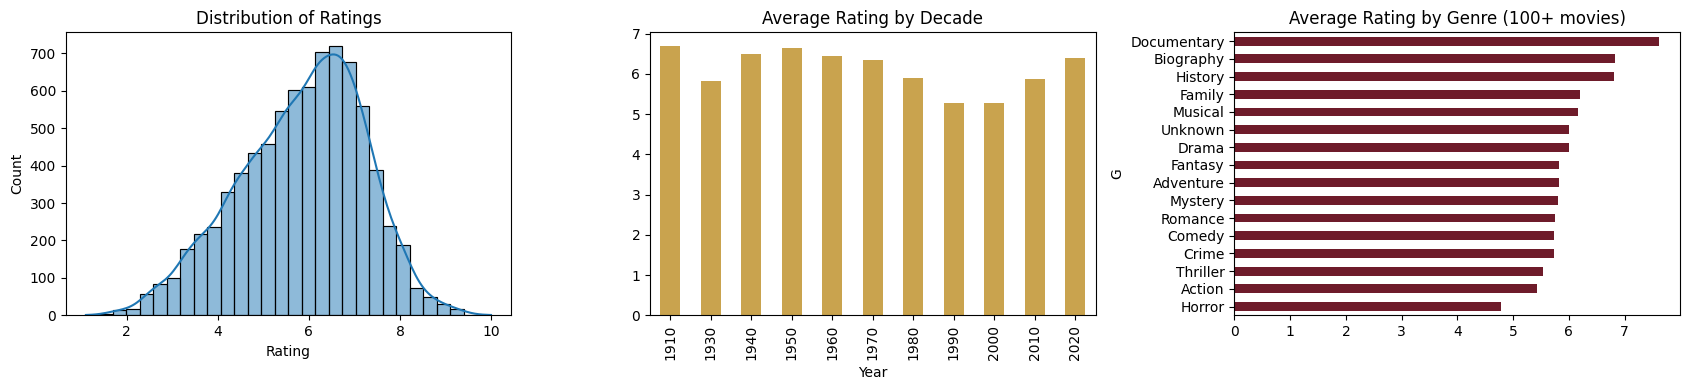

Rating      1.00
Votes       0.13
Duration   -0.03
Year       -0.17
Name: Rating, dtype: float64


In [11]:
#clean the data and explore it
# 1. Keep only movies that have a rating
data = df.dropna(subset=["Rating"]).copy()

# 2. Turn text columns into numbers
data["Year"] = pd.to_numeric(data["Year"].str.extract(r"(\d{4})")[0])
data["Duration"] = pd.to_numeric(data["Duration"].str.extract(r"(\d+)")[0])
data["Votes"] = pd.to_numeric(data["Votes"].str.replace(",", ""), errors="coerce")

# 3. Fill missing values
data["Duration"] = data["Duration"].fillna(data["Duration"].median())
data["Votes"] = data["Votes"].fillna(data["Votes"].median())
for col in ["Genre", "Director", "Actor 1", "Actor 2", "Actor 3"]:
    data[col] = data[col].fillna("Unknown")

print("Rated movies:", data.shape[0])
print(data[["Year", "Duration", "Votes", "Rating"]].isnull().sum())
print()

# 4. Explore
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

sns.histplot(data["Rating"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Distribution of Ratings")

decade = (data["Year"] // 10 * 10).astype(int)
data.groupby(decade)["Rating"].mean().plot(kind="bar", ax=ax[1], color="#c9a34e")
ax[1].set_title("Average Rating by Decade")

genres = data.assign(G=data["Genre"].str.split(", ")).explode("G")
top = genres.groupby("G")["Rating"].agg(["count", "mean"])
top = top[top["count"] >= 100].sort_values("mean")
top["mean"].plot(kind="barh", ax=ax[2], color="#6e1b2a")
ax[2].set_title("Average Rating by Genre (100+ movies)")

plt.tight_layout()
plt.show()

print(data[["Rating", "Votes", "Duration", "Year"]].corr().round(2)["Rating"])

In [12]:
#split the data and buil features
from sklearn.model_selection import train_test_split, KFold

# 1. Split FIRST, so the test movies stay unseen
train_df, test_df = train_test_split(data, test_size=0.2, random_state=42)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

SMOOTH = 5                         # pulls directors with few movies toward the average
ACTORS = ["Actor 1", "Actor 2", "Actor 3"]

def build_maps(fit_df):
    g = fit_df["Rating"].mean()
    d = fit_df[fit_df["Director"] != "Unknown"].groupby("Director")["Rating"].agg(["sum", "count"])
    long = pd.concat([fit_df[[c, "Rating"]].rename(columns={c: "Actor"}) for c in ACTORS])
    long = long[long["Actor"] != "Unknown"]
    a = long.groupby("Actor")["Rating"].agg(["sum", "count"])
    return g, d, a

def apply_maps(df_, maps):
    g, d, a = maps
    def score(name, table):
        if name in table.index:
            s, n = table.loc[name, "sum"], table.loc[name, "count"]
            return (s + SMOOTH * g) / (n + SMOOTH), n
        return g, 0
    out = pd.DataFrame(index=df_.index)
    dd = [score(x, d) for x in df_["Director"]]
    out["DirectorScore"] = [x[0] for x in dd]
    out["DirectorMovies"] = [x[1] for x in dd]
    sc, ct = [], []
    for _, r in df_[ACTORS].iterrows():
        res = [score(x, a) for x in r]
        sc.append(np.mean([x[0] for x in res]))
        ct.append(np.mean([x[1] for x in res]))
    out["CastScore"] = sc
    out["CastExperience"] = ct
    return out

# 2. Star power for training movies: out-of-fold, so no leakage
star_cols = ["DirectorScore", "DirectorMovies", "CastScore", "CastExperience"]
star_train = pd.DataFrame(index=train_df.index, columns=star_cols, dtype=float)
for fit_idx, val_idx in KFold(5, shuffle=True, random_state=42).split(train_df):
    maps = build_maps(train_df.iloc[fit_idx])
    star_train.iloc[val_idx] = apply_maps(train_df.iloc[val_idx], maps).values

# 3. Star power for test movies: uses ALL training movies
star_test = apply_maps(test_df, build_maps(train_df))

# 4. Basic features and genre columns
top_genres = (train_df["Genre"].str.split(", ").explode().value_counts()
              .loc[lambda s: s >= 100].index.drop("Unknown", errors="ignore"))

def basics(df_):
    out = df_[["Year", "Duration"]].copy()
    out["LogVotes"] = np.log1p(df_["Votes"])
    for gname in top_genres:
        out["G_" + gname] = df_["Genre"].apply(lambda s, gname=gname: int(gname in s.split(", ")))
    return out

X_train = pd.concat([basics(train_df), star_train], axis=1)
X_test = pd.concat([basics(test_df), star_test], axis=1)
y_train, y_test = train_df["Rating"], test_df["Rating"]

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Missing values:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print("Genres used:", list(top_genres))
X_train[star_cols].describe().round(2)

Train: (6335, 21)  Test: (1584, 21)
Missing values: 0 0
Genres used: ['Drama', 'Action', 'Romance', 'Comedy', 'Crime', 'Thriller', 'Family', 'Musical', 'Adventure', 'Mystery', 'Horror', 'Fantasy', 'Documentary', 'Biography']


,DirectorScore,DirectorMovies,CastScore,CastExperience
count,6335.00,6335.00,6335.00,6335.00
mean,5.84,4.85,5.82,21.57
std,0.37,6.40,0.31,21.95
min,4.43,0.00,4.76,0.00
25%,5.70,0.00,5.62,3.00
50%,5.83,2.00,5.83,14.00
75%,6.00,7.00,6.01,34.67
max,7.17,33.00,6.78,125.33


In [13]:
#compare the models
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear (Ridge)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

setups = {
    "With Votes": list(X_train.columns),
    "Without Votes": [c for c in X_train.columns if c != "LogVotes"],
}

rows = []
for setup, cols in setups.items():
    for name, model in models.items():
        model.fit(X_train[cols], y_train)
        pred = model.predict(X_test[cols])
        rows.append([setup, name,
                     round(mean_absolute_error(y_test, pred), 3),
                     round(np.sqrt(mean_squared_error(y_test, pred)), 3),
                     round(r2_score(y_test, pred), 3)])

# Baseline: always guess the average rating
base = np.full(len(y_test), y_train.mean())
rows.append(["Baseline", "Always predict average",
             round(mean_absolute_error(y_test, base), 3),
             round(np.sqrt(mean_squared_error(y_test, base)), 3),
             round(r2_score(y_test, base), 3)])

results = pd.DataFrame(rows, columns=["Setup", "Model", "MAE", "RMSE", "R2"])
print(results.to_string(index=False))

        Setup                  Model   MAE  RMSE     R2
   With Votes         Linear (Ridge) 0.852 1.109  0.339
   With Votes          Random Forest 0.782 1.035  0.424
   With Votes      Gradient Boosting 0.784 1.031  0.428
Without Votes         Linear (Ridge) 0.888 1.142  0.298
Without Votes          Random Forest 0.864 1.117  0.329
Without Votes      Gradient Boosting 0.855 1.104  0.345
     Baseline Always predict average 1.107 1.365 -0.002


Test MAE: 0.784
Test R2 : 0.428
Predictions within 0.5 stars: 42.6 %
Predictions within 1.0 star : 70.9 %


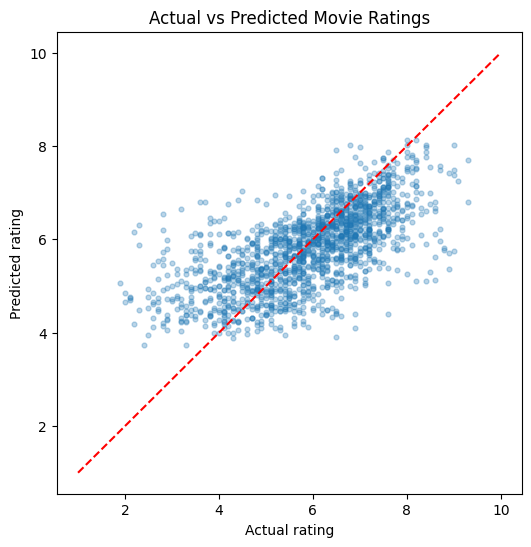

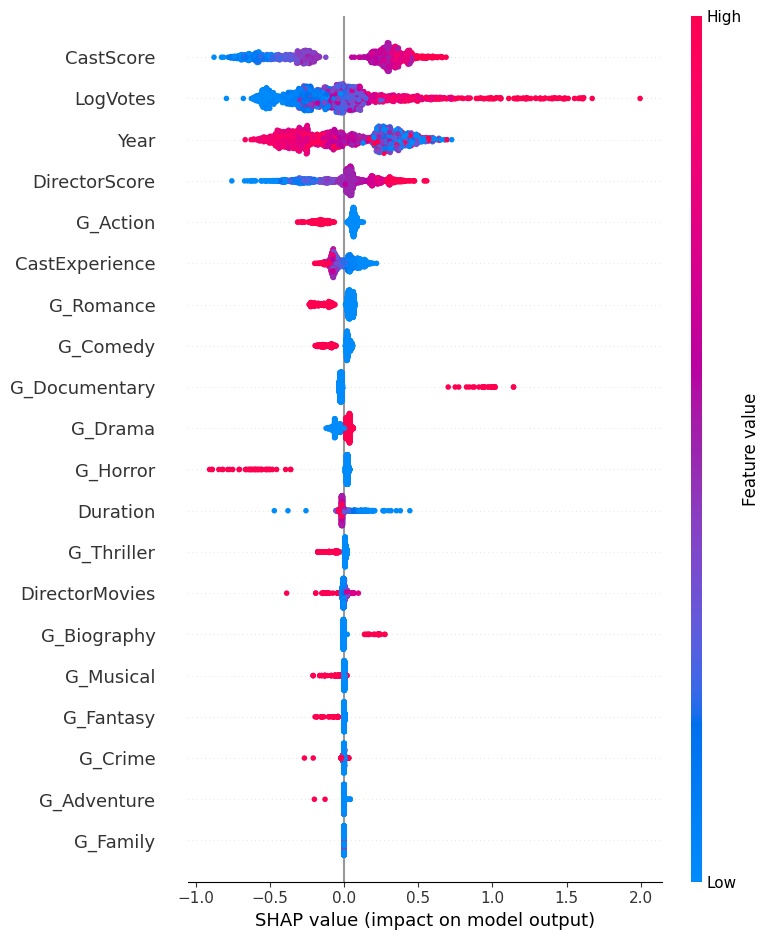

In [14]:
!pip install shap -q
import shap
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Final model, using all features
final_model = GradientBoostingRegressor(random_state=42)
final_model.fit(X_train, y_train)
pred = final_model.predict(X_test)

print("Test MAE:", round(mean_absolute_error(y_test, pred), 3))
print("Test R2 :", round(r2_score(y_test, pred), 3))
err = np.abs(y_test - pred)
print("Predictions within 0.5 stars:", round((err <= 0.5).mean() * 100, 1), "%")
print("Predictions within 1.0 star :", round((err <= 1.0).mean() * 100, 1), "%")

# 2. Actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.3, s=12)
plt.plot([1, 10], [1, 10], "r--")
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating")
plt.title("Actual vs Predicted Movie Ratings")
plt.show()

# 3. SHAP: what drives the predictions?
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

In [15]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.ensemble import GradientBoostingRegressor
!pip install shap -q
import shap

# ---------- 1. Build the predictor (about a minute, runs once) ----------
full = data.reset_index(drop=True)
nv_cols = [c for c in X_train.columns if c != "LogVotes"]          # no Votes: works for new movies
movie_model = GradientBoostingRegressor(random_state=42).fit(X_train[nv_cols], y_train)
low_model = GradientBoostingRegressor(loss="quantile", alpha=0.1, random_state=42).fit(X_train[nv_cols], y_train)
high_model = GradientBoostingRegressor(loss="quantile", alpha=0.9, random_state=42).fit(X_train[nv_cols], y_train)
explainer = shap.TreeExplainer(movie_model)
look = build_maps(full)                                              # track records from ALL rated movies

# ---------- 2. Names for the dropdowns (all names in your dataset) ----------
director_names = full.loc[full["Director"] != "Unknown", "Director"].value_counts().index.tolist()
actor_names = (pd.concat([full[c] for c in ["Actor 1", "Actor 2", "Actor 3"]])
               .loc[lambda s: s != "Unknown"].value_counts().index.tolist())
genre_names = list(top_genres)

NICE = {"Year": "release year", "Duration": "running time", "DirectorScore": "director's track record",
        "DirectorMovies": "director's experience", "CastScore": "cast track record",
        "CastExperience": "cast experience"}
def nice(c):
    return "genre: " + c[2:] if c.startswith("G_") else NICE.get(c, c)

def predict_movie(year, duration, genres, director, actors):
    a = (list(actors) + ["", "", ""])[:3]
    row = pd.DataFrame([{"Year": year, "Duration": duration,
        "Genre": ", ".join(genres) if genres else "Unknown",
        "Director": director.strip() or "Unknown", "Actor 1": a[0].strip() or "Unknown",
        "Actor 2": a[1].strip() or "Unknown", "Actor 3": a[2].strip() or "Unknown"}])
    feats = pd.concat([basics(row.assign(Votes=1)).drop(columns="LogVotes"),
                       apply_maps(row, look)], axis=1)[nv_cols]
    r = min(10, max(1, float(movie_model.predict(feats)[0])))
    lo = min(r, max(1, float(low_model.predict(feats)[0])))
    hi = max(r, min(10, float(high_model.predict(feats)[0])))
    sv = explainer.shap_values(feats)[0]
    top = sorted(zip(nv_cols, sv), key=lambda x: -abs(x[1]))[:4]
    return r, lo, hi, top, feats

# ---------- 3. The dropdown form ----------
style = {"description_width": "110px"}
wide = widgets.Layout(width="420px")
year_w = widgets.IntSlider(value=2024, min=1930, max=2026, description="Release year", style=style, layout=wide)
dur_w = widgets.IntSlider(value=140, min=60, max=240, description="Duration (min)", style=style, layout=wide)
genre_w = widgets.SelectMultiple(options=genre_names, value=("Drama",), rows=6,
                                 description="Genres (Ctrl+click)", style=style, layout=wide)
dir_w = widgets.Combobox(options=director_names, placeholder="Type or pick a director", ensure_option=False,
                         description="Director", style=style, layout=wide)
act_ws = [widgets.Combobox(options=actor_names, placeholder="Type or pick an actor", ensure_option=False,
                           description=f"Actor {i}", style=style, layout=wide) for i in (1, 2, 3)]
btn = widgets.Button(description="Predict rating", button_style="success", icon="star")
out = widgets.Output()

def on_click(_):
    with out:
        clear_output()
        r, lo, hi, top, f = predict_movie(year_w.value, dur_w.value, list(genre_w.value),
                                          dir_w.value, [x.value for x in act_ws])
        print(f"⭐ Predicted rating: {r:.1f} / 10")
        print(f"   Likely range (80% of the time): {lo:.1f} to {hi:.1f}")
        print()
        print("Why this rating (biggest reasons):")
        for c, v in top:
            print(f"   {'▲ raises' if v > 0 else '▼ lowers'} by {abs(v):.2f}  ←  {nice(c)}")
        print()
        print(f"Director history: {int(f['DirectorMovies'].iloc[0])} movies found, score {f['DirectorScore'].iloc[0]:.2f}")
        print(f"Cast history: average {f['CastExperience'].iloc[0]:.0f} movies each, score {f['CastScore'].iloc[0]:.2f}")
        print("(Names not in the dataset get the overall average score.)")

btn.on_click(on_click)
display(widgets.VBox([year_w, dur_w, genre_w, dir_w, *act_ws, btn, out]))